# Preliminaries

Evaluation of **Feature Attribution Methods** on the test set using the library `Xplique`.

In [1]:
!pwd
import sys
sys.path.append('./xplique/')
sys.path.append('./wingbeats/')

/mnt/KInsektDaten/teo


In [2]:
import numpy as np
from matplotlib import pyplot as plt
import tensorflow as tf
from tensorflow.keras.layers.experimental.preprocessing import Rescaling

from beexplainable.beexplainable.utils import metafile_readers as mr # an extra prefix beexplainable. may be needed
from beexplainable.beexplainable.modelling import classifiers as cls
from beexplainable.beexplainable.preprocessing import parsers as ps
from wingbeats import modelling as wm # for building simple classifiers

from xplique.plots import plot_attributions

/home/tchiaburu/anaconda3/envs/tf2_gpu/lib/python3.9/site-packages/scipy/__init__.py:138: UserWarning: A NumPy version >=1.16.5 and <1.23.0 is required for this version of SciPy (detected version 1.23.1)
  warnings.warn(f"A NumPy version >={np_minversion} and <{np_maxversion} is required for this version of "


In [3]:
compress_B_lucorum = True  # compress the 4 difficult species together

metafolder = './beexplainable/metafiles/Bees_Christian/'
spec_subfolder = '22_species/' if compress_B_lucorum else '25_species/'

BEES_PATH = '../data/data_lstudio/Bees_Christian/'
IMAGES_PATH = metafolder + 'images.txt'
IMAGES_LABELS_PATH = metafolder + spec_subfolder + 'image_class_labels.txt'
CLASSES_PATH = metafolder + spec_subfolder + 'classes.txt'

MODELS_PATH  = './beexplainable/models/'
FIGURES_PATH = './beexplainable/figures/training_curves/'

# Load images

In [4]:
batch_size = 8
img_height = img_width = 224

# Read file IDs and corresponding class labels
img_dict = mr.metafile_to_dict(IMAGES_PATH)
img_label_dict = mr.metafile_to_dict(IMAGES_LABELS_PATH)
file_ids = list( img_dict.keys() )
y_true   = list( img_label_dict.values() )
y_true   = np.asarray(y_true, dtype = np.uint8) - 1
# Note! Labels in CUB format start at index 1, but cross entropy needs to start at 0

# Read class names
cls_dict = mr.metafile_to_dict(CLASSES_PATH)
classes = list( cls_dict.values() )

In [5]:
# Get dictionary of file IDs and file names
# Convert it into a tf.StaticHashTable to be able to retrieve dictionary values during eager execution
# Alternative: tf.gather
img_lookup = tf.lookup.StaticHashTable(tf.lookup.KeyValueTensorInitializer(file_ids,
                                                                           list(img_dict.values())),
                                       default_value = 'No file')

# Parsing function for tf.Dataset
parse_image_lab = lambda file_id, label: (ps.parse_image(file_id, img_lookup, img_width, img_height, BEES_PATH),
                                          label)

In [6]:
# Conversion to tf.Dataset
test_set = ps.parse_to_dataset(file_ids, y_true, parse_image_lab)
test_set = test_set.cache().batch(batch_size).prefetch(tf.data.experimental.AUTOTUNE)

# Normalize raw images (first item in the tuples, second is the mask)
normalization_layer = Rescaling(1./255)
test_set = test_set.map(lambda x, y: (normalization_layer(x), y))

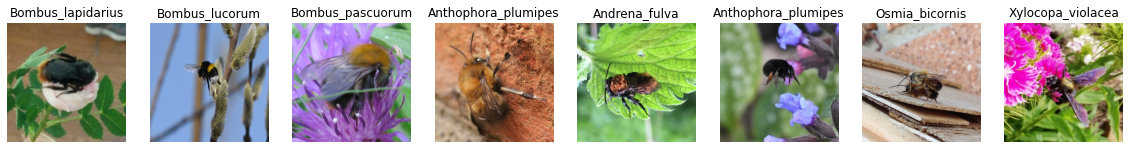

In [7]:
# Plot a few examples
plt.figure(figsize = (20, 20))
num_cols = min(8, batch_size)
with tf.device('/CPU:0'):
    for images, labels in test_set.take(1):
        for i in range(num_cols):
            plt.subplot(1, num_cols, i + 1)
            plt.imshow(images[i])
            plt.title(cls_dict[str(labels[i].numpy()+1)])
            plt.axis("off")
plt.show()

In [8]:
for image_batch, labels_batch in test_set.take(1):
    print(image_batch.shape)
    print(labels_batch[0])

(8, 224, 224, 3)
tf.Tensor(0, shape=(), dtype=uint8)


# Load Model

In [9]:
# Define initial training and other model parameters
drop_rate = 0.5
lr, reg = 1e-4, 1e-4 # parameters optimized in HPO notebook
in_shape = (img_width, img_height, 3)

constructor, out_shape =  wm.build_simple_classifier, len(classes)
loss = 'sparse_categorical_crossentropy'
metrics = ['accuracy', tf.keras.metrics.SparseTopKCategoricalAccuracy(k=3, name='top_3_accuracy')]

# Define whether to load fine grained backbone weights
load_pretrained_backbone = True # if False, ImageNet weights are loaded
# ResNet50 weights trained on iNat2021
# https://github.com/visipedia/newt/tree/main/benchmark
pretrained_weights_file = MODELS_PATH + 'backbones/resnet50_simclr_v1_inat20_no_top_500.h5' if load_pretrained_backbone else None

# Derive model name
input_form = 'raw' # raw, masked, bbox, masked_bbox
#dataset_type = 'mini' if use_mini_dataset else 'all'
init = 'iNat' if load_pretrained_backbone else 'Imagenet'
model_name = 'ResNet50_' + init + '_' + input_form
weights_file = MODELS_PATH + 'all/' + spec_subfolder + model_name + '/' + model_name + '.h5' # path from which to load weights

# The pretrained ResNet on iNat already has a GlobalAvgPooling layer
add_global_avg = False if load_pretrained_backbone else True

# Whether to retrain the backbone or not
trainable = True

In [10]:
# Build and compile
tf.keras.backend.clear_session()
cnn_name = 'CNN_Blocks_' + model_name

cnn = cls.CNN_ResNet50(in_shape, drop_rate, add_global_avg = add_global_avg, trainable = trainable,
                       weights_file = pretrained_weights_file, name = cnn_name)

model = constructor(in_shape, out_shape, cnn, reg,
                    input_name = 'jpg', model_name = model_name)

model.load_weights(weights_file)

model.compile(tf.keras.optimizers.Adam(lr), loss = loss, metrics = metrics)

# XAI

## Simple example: Saliency Maps

Keep in mind that the **different methods share the same api**:


``` python
explainer = ExplainerClass(model, batch_size, *explainer_params)
explanations = explainer(inputs, labels)
```



In [11]:
# Convert sparse labels into one-hot-vectors
labels_batch_cat = tf.keras.utils.to_categorical(labels_batch, 22 if compress_B_lucorum else 25)

In [12]:
labels_batch[5]

<tf.Tensor: shape=(), dtype=uint8, numpy=3>

In [13]:
labels_batch_cat[5]

array([0., 0., 0., 1., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0.,
       0., 0., 0., 0., 0.], dtype=float32)

In [14]:
from xplique.attributions import Saliency

# create an explainer and generate explanations
explainer = Saliency(model)
explanations = explainer(image_batch, labels_batch_cat) # `explainer.explain(inputs, labels)` also works

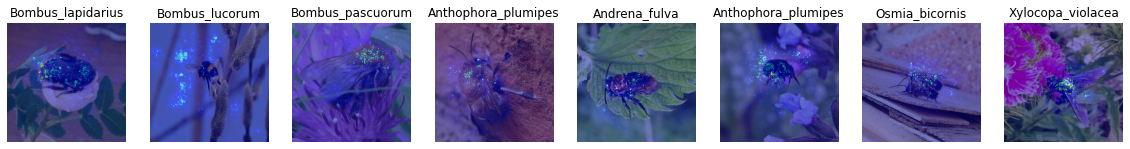

In [15]:
# Plot a few examples
plt.figure(figsize = (20, 20))
num_cols = min(8, batch_size)
with tf.device('/CPU:0'):
    for images, labels in test_set.take(1):
        for i in range(num_cols):
            plt.subplot(1, num_cols, i + 1)
            plt.imshow(images[i])
            plt.imshow(explanations[i], cmap="jet", alpha=0.5)
            plt.title(cls_dict[str(labels[i].numpy()+1)])
            plt.axis("off")
plt.show()

## Comparing multiple methods

Method: Saliency


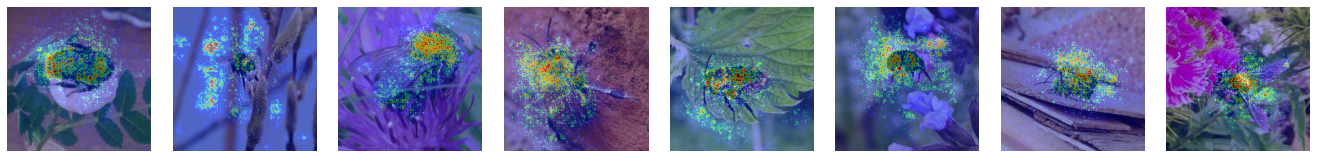



Method: GradientInput


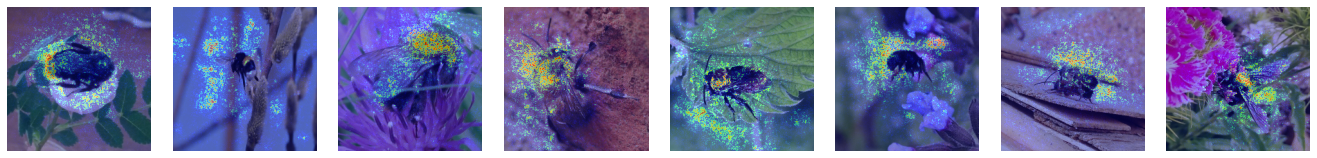



Method: IntegratedGradients


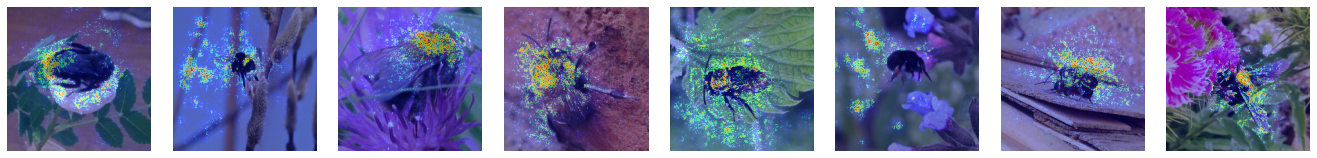



Method: SmoothGrad


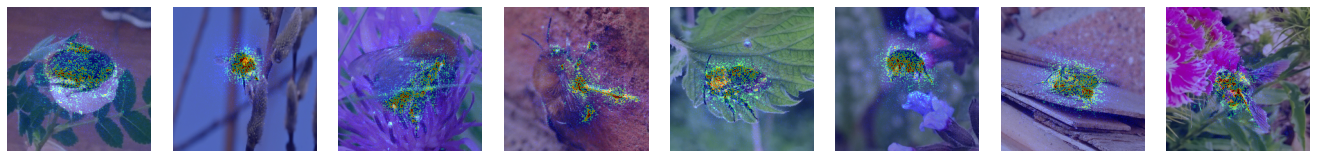



Method: SquareGrad


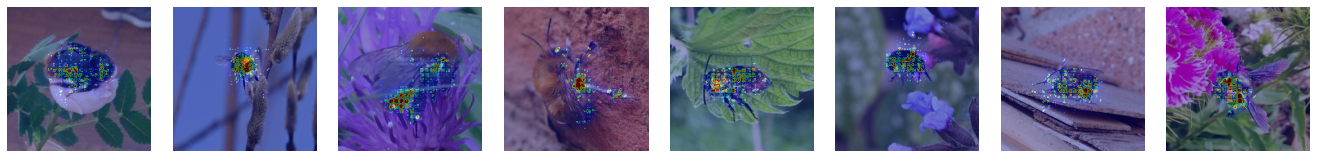



Method: VarGrad


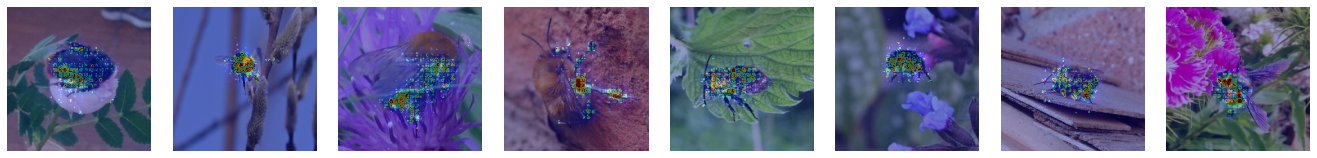



Method: Occlusion


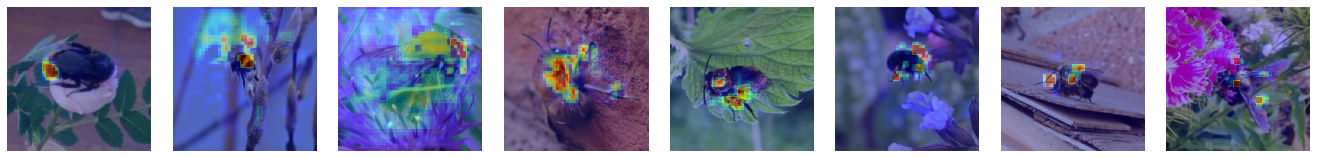



Method: Rise


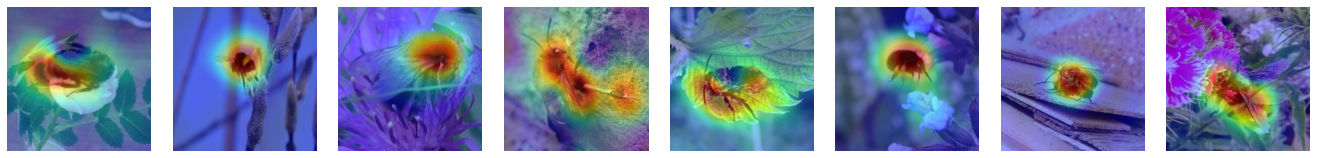



Method: Lime


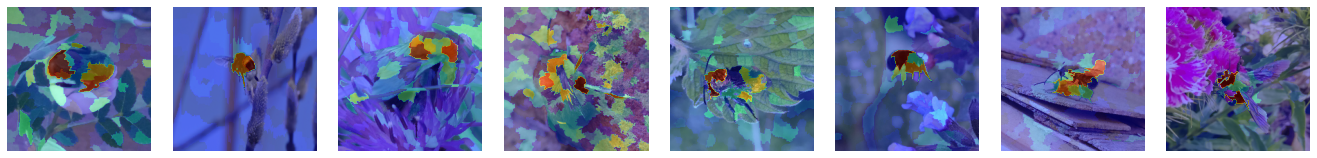



Method: KernelShap


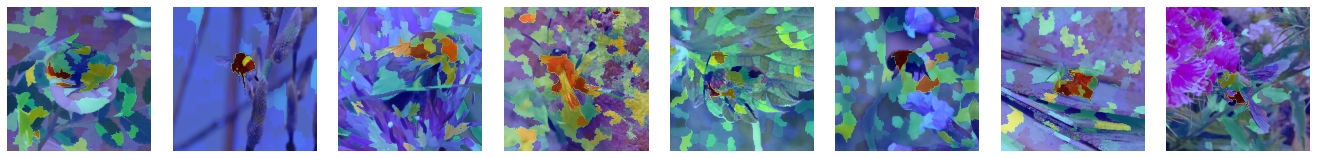

In [17]:
from xplique.attributions import (Saliency, GradientInput, IntegratedGradients, SmoothGrad, VarGrad,
                                  SquareGrad, GradCAM, Occlusion, Rise, GuidedBackprop,
                                  Lime, KernelShap)

# explaining the logits is to explain the class,
# explaining the softmax is to explain why this class is more likely
# it is therefore recommended to explain the logit
model.layers[-1].activation = tf.keras.activations.linear

explainers = [
             Saliency(model),
             GradientInput(model),
             #GuidedBackprop(model), # monte_carlo_dropout not understood
             IntegratedGradients(model, steps=80, batch_size=batch_size),
             SmoothGrad(model, nb_samples=80, batch_size=batch_size),
             SquareGrad(model, nb_samples=80, batch_size=batch_size),
             VarGrad(model, nb_samples=80, batch_size=batch_size),
             #GradCAM(model, conv_layer=1), # invalid reduction dimension
             Occlusion(model, patch_size=10, patch_stride=5, batch_size=batch_size),
             Rise(model, nb_samples=4000, batch_size=batch_size),
             Lime(model, nb_samples = 1000),
             KernelShap(model, nb_samples = 1000)
]

for explainer in explainers:

  explanations = explainer(image_batch, labels_batch_cat)

  print(f"Method: {explainer.__class__.__name__}")
  plot_attributions(explanations, image_batch, img_size=2., cmap='jet', alpha=0.4,
                    cols=batch_size, absolute_value=True, clip_percentile=0.5)
  plt.show()
  print("\n")